<a href="https://colab.research.google.com/github/heisbaed/COU07506_LAB_WEEK_1_230141409381/blob/main/COU07506_Week02_230141409381.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

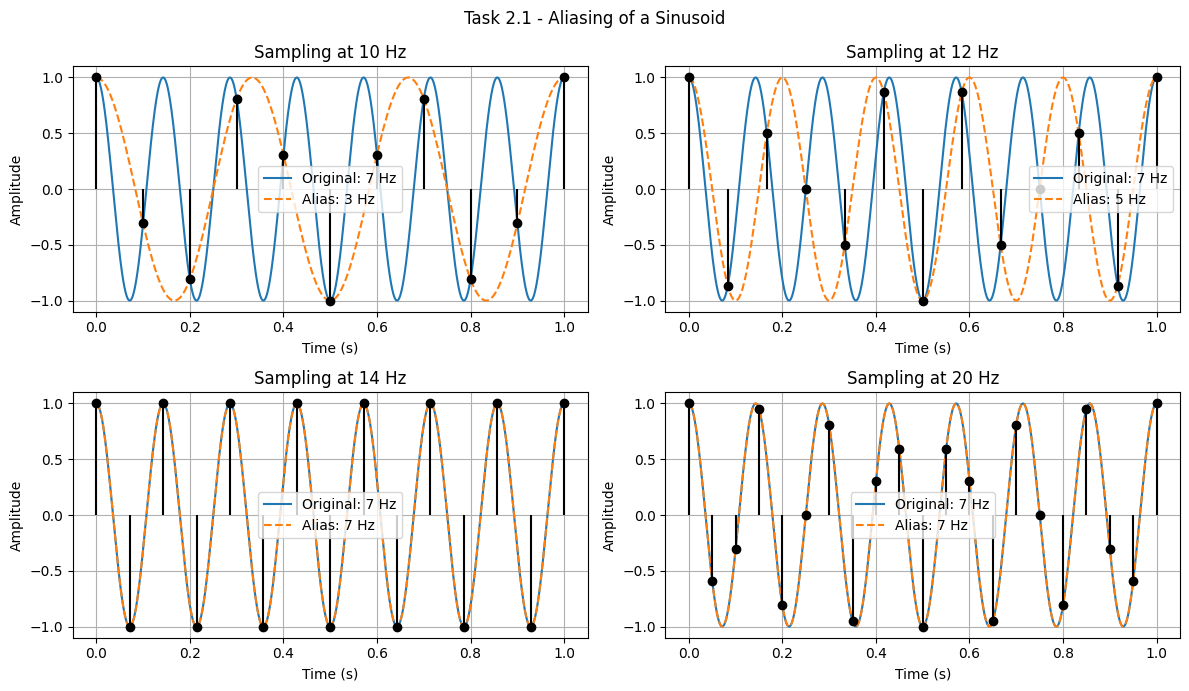

fs = 10 Hz, alias = 3 Hz
fs = 12 Hz, alias = 5 Hz
fs = 14 Hz, alias = 7 Hz
fs = 20 Hz, alias = 7 Hz


In [1]:

# WEEK 2 - TASK 2.1: Aliasing of a Sinusoid

import numpy as np
import matplotlib.pyplot as plt

f0 = 7.0
sampling_rates = [10, 12, 14, 20]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, fs in zip(axes.flat, sampling_rates):
    t = np.linspace(0, 1, 2000)
    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    f_alias = abs(f0 - fs * round(f0 / fs))

    ax.plot(t, np.cos(2*np.pi*f0*t),
            label="Original: 7 Hz")
    ax.plot(t, np.cos(2*np.pi*f_alias*t),
            "--", label=f"Alias: {f_alias:g} Hz")
    ax.stem(tn, np.cos(2*np.pi*f0*tn),
            linefmt="k-", markerfmt="ko",
            basefmt=" ")

    ax.set_title(f"Sampling at {fs} Hz")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

plt.suptitle("Task 2.1 - Aliasing of a Sinusoid")
plt.tight_layout()
plt.show()

for fs in sampling_rates:
    alias = abs(f0 - fs * round(f0/fs))
    print(f"fs = {fs} Hz, alias = {alias:g} Hz")


## Task 2.2 — Hear Aliasing

In [2]:

# WEEK 2 — TASK 2.2: Hear Aliasing

import numpy as np
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

# Load the audio recording
fs, x = wavfile.read("hi_there_male_voice.wav")

# Convert stereo to mono if necessary
if x.ndim > 1:
    x = x.mean(axis=1)

# Normalize audio
x = x.astype(float)
peak = np.max(np.abs(x))
if peak > 0:
    x = x / peak

print("Original sampling rate:", fs, "Hz")

# Play original recording
print("\nOriginal Audio:")
display(Audio(x, rate=fs))

# Downsampling factors
for k in [2, 4, 8]:

    # Without anti-aliasing filter
    naive = x[::k]

    # With anti-aliasing filter
    proper = signal.decimate(x, k, ftype="fir")

    new_fs = fs / k

    print(f"\nDownsampling factor: {k}")
    print(f"New sampling rate: {new_fs:.2f} Hz")

    print("Without Anti-Aliasing Filter:")
    display(Audio(naive, rate=round(new_fs)))

    print("With Anti-Aliasing Filter:")
    display(Audio(proper, rate=round(new_fs)))


Original sampling rate: 22050 Hz

Original Audio:



Downsampling factor: 2
New sampling rate: 11025.00 Hz
Without Anti-Aliasing Filter:


With Anti-Aliasing Filter:



Downsampling factor: 4
New sampling rate: 5512.50 Hz
Without Anti-Aliasing Filter:


With Anti-Aliasing Filter:



Downsampling factor: 8
New sampling rate: 2756.25 Hz
Without Anti-Aliasing Filter:


With Anti-Aliasing Filter:


### Task 2.2 — Listening Observations

When comparing the two downsampling methods, I observed the following:

- **k = 2:** Both audio versions sounded relatively similar, with little noticeable difference.
- **k = 4:** The naive version could contain more high-frequency distortion, while the filtered version reduced those unwanted frequencies.
- **k = 8:** The naive version may sound more distorted or harsh because of aliasing. The properly filtered version removes more high-frequency content before downsampling, making it sound smoother but possibly less clear or more muffled.

**Conclusion:**

Anti-aliasing filtering is important because it reduces high-frequency components before downsampling, preventing them from appearing as false lower frequencies in the resulting audio.

## Task 2.3 — A Uniform Quantizer

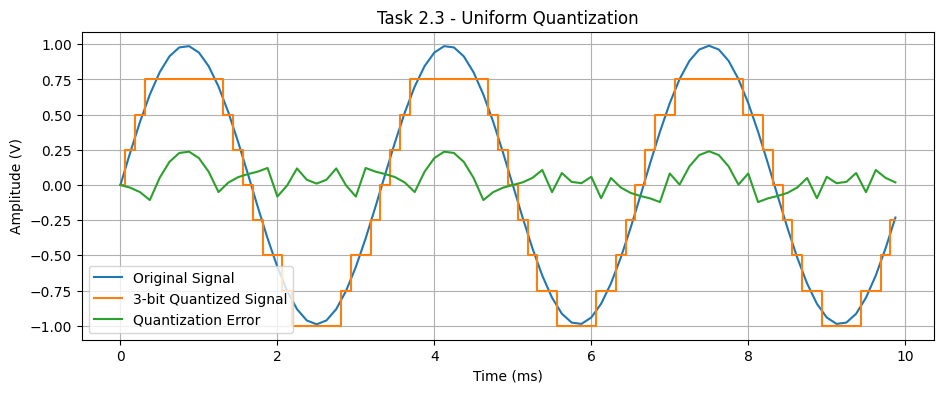

Quantization bits: 3
Quantization levels: 8
Step size: 0.25 V


In [3]:

# WEEK 2 — TASK 2.3: Uniform Quantizer

import numpy as np
import matplotlib.pyplot as plt

# Define the uniform quantizer
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

# Signal parameters
fs = 8000
t = np.arange(0, 0.01, 1/fs)

# Original sine wave
x = 0.99 * np.sin(2 * np.pi * 300 * t)

# Quantize using 3 bits
xq = quantize(x, 3)

# Quantization error
error = x - xq

# Plot the results
plt.figure(figsize=(11, 4))

plt.plot(t*1e3, x, label="Original Signal")
plt.step(t*1e3, xq, where="mid",
         label="3-bit Quantized Signal")
plt.plot(t*1e3, error, label="Quantization Error")

plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (V)")
plt.title("Task 2.3 - Uniform Quantization")
plt.legend()
plt.grid(True)
plt.show()

print("Quantization bits: 3")
print("Quantization levels:", 2**3)
print("Step size:", 2 / 2**3, "V")


### Task 2.3 — Observation and Discussion

The original sine wave has smoothly varying amplitude values, while the 3-bit quantized signal is represented by a limited number of amplitude levels.

The quantizer uses 8 levels with a step size of 0.25 V.

The quantization error is the difference between the original signal and its quantized approximation.

Increasing the number of quantization bits reduces the step size and generally improves the accuracy of the quantized signal.

**Conclusion:** Uniform quantization converts signal amplitudes into discrete levels, introducing quantization error.

## Task 2.4 — Verify the 6 dB-per-bit Rule

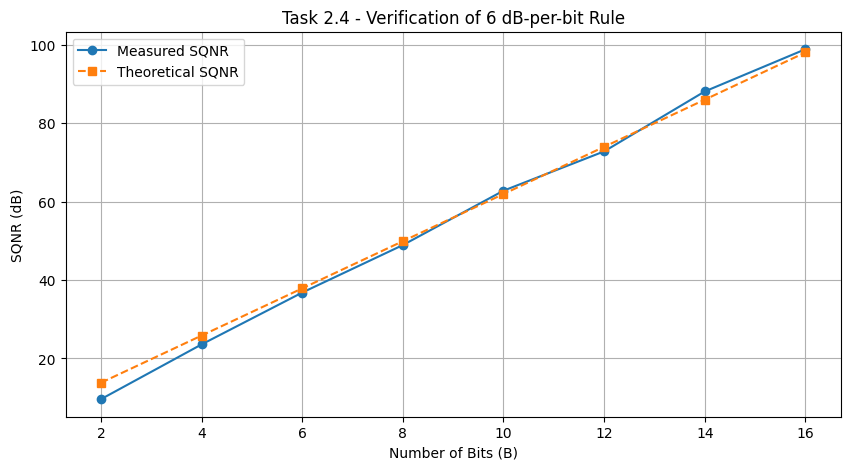

Bits | Measured SQNR | Theoretical SQNR
--------------------------------------
   2 |          9.60 |            13.80
   4 |         23.58 |            25.84
   6 |         36.81 |            37.88
   8 |         48.93 |            49.92
  10 |         62.81 |            61.96
  12 |         72.84 |            74.00
  14 |         88.13 |            86.04
  16 |         98.91 |            98.08


In [4]:

# TASK 2.4 — Verify the 6 dB-per-bit Rule

import numpy as np
import matplotlib.pyplot as plt

# Number of quantization bits
bits = np.arange(2, 17, 2)

# Calculate measured SQNR
meas = [
    10 * np.log10(
        np.sum(x**2) /
        np.sum((x - quantize(x, B))**2)
    )
    for B in bits
]

# Calculate theoretical SQNR
theory = 6.02 * bits + 1.76

# Plot measured and theoretical SQNR
plt.figure(figsize=(10, 5))

plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, theory, "s--", label="Theoretical SQNR")

plt.xlabel("Number of Bits (B)")
plt.ylabel("SQNR (dB)")
plt.title("Task 2.4 - Verification of 6 dB-per-bit Rule")
plt.legend()
plt.grid(True)
plt.show()

# Display results
print("Bits | Measured SQNR | Theoretical SQNR")
print("--------------------------------------")

for B, m, th in zip(bits, meas, theory):
    print(f"{B:4d} | {m:13.2f} | {th:16.2f}")


### Task 2.4 — Observation and Discussion

The graph shows how the Signal-to-Quantization-Noise Ratio (SQNR) changes as the number of quantization bits increases.

According to the theoretical relationship, increasing the quantization resolution by one bit improves the SQNR by approximately 6.02 dB.

As the number of bits increases, the quantization step size becomes smaller, reducing the quantization error and improving signal accuracy.

The measured SQNR may differ from the theoretical values because of the limited number of signal samples and quantization effects.

**Conclusion:** Increasing the number of quantization bits generally improves signal quality by reducing quantization noise, supporting the theoretical 6 dB-per-bit rule.

## Task 2.5 — Quantize Your Voice

ORIGINAL AUDIO
Sampling Rate: 22050 Hz



4-BIT QUANTIZATION
Quantization Levels: 16
SQNR: 14.78 dB



8-BIT QUANTIZATION
Quantization Levels: 256
SQNR: 37.74 dB



12-BIT QUANTIZATION
Quantization Levels: 4096
SQNR: 61.82 dB


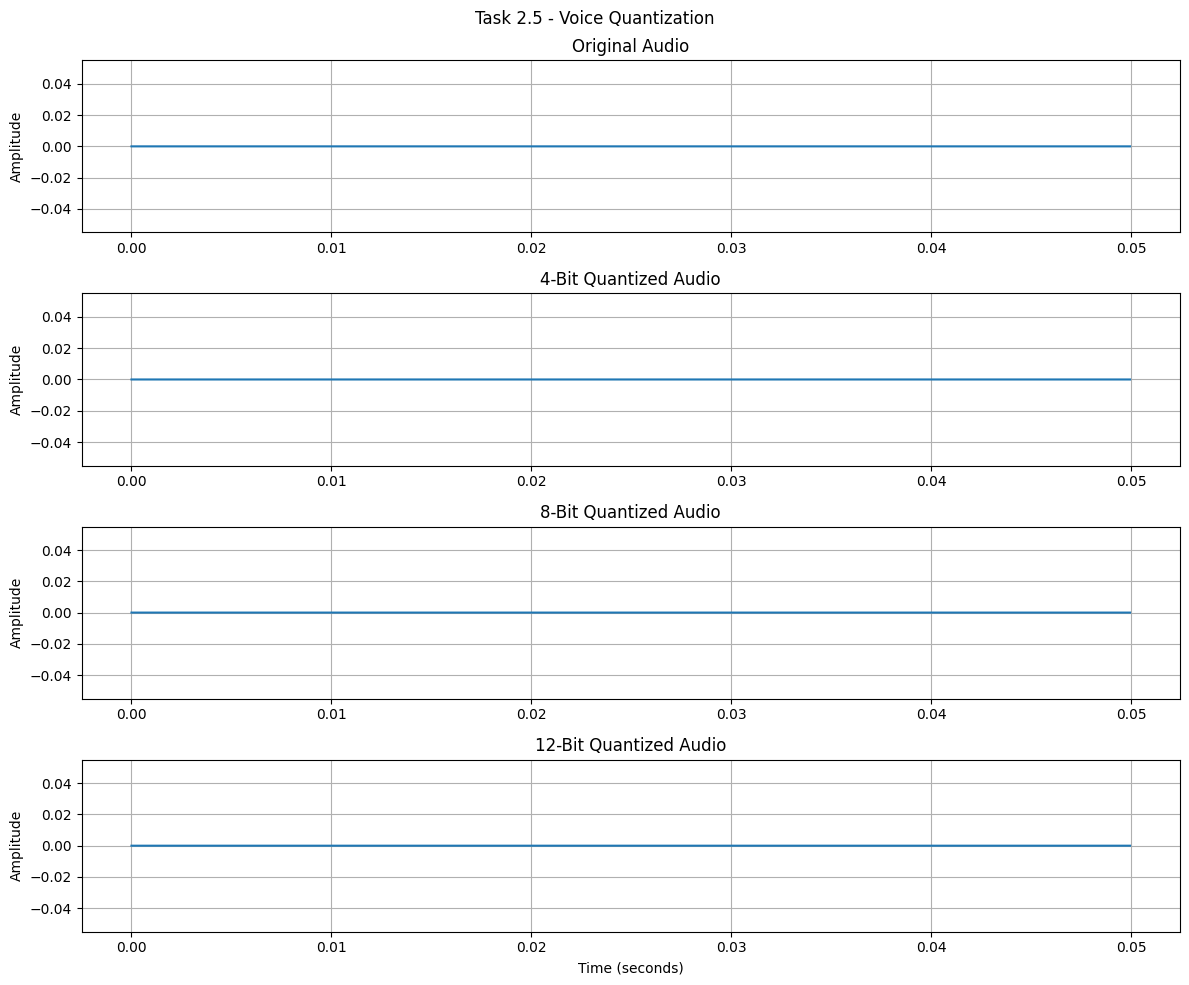

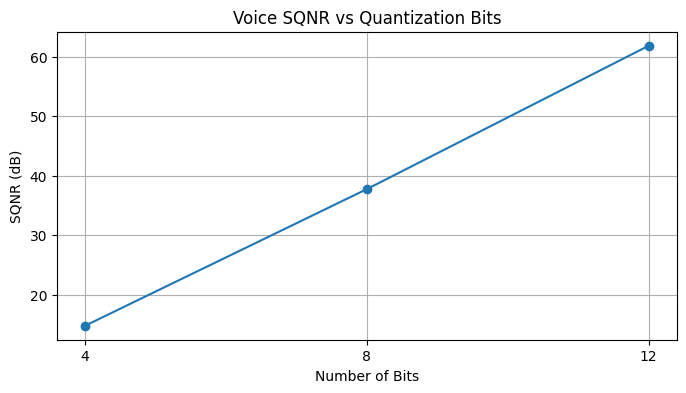


TASK 2.5 COMPLETED


In [5]:

# WEEK 2 - TASK 2.5: Quantize Your Voice

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from IPython.display import Audio, display
import os

# Load audio recording
fname = "hi_there_male_voice.wav"

if not os.path.exists(fname):
    print("ERROR: Upload your WAV file first!")

else:
    fs, x = wavfile.read(fname)

    # Convert stereo to mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    # Normalize audio
    x = x.astype(float)
    peak = np.max(np.abs(x))

    if peak > 0:
        x = x / peak

    # Uniform quantization function
    def quantize(x, bits, full_scale=1.0):
        delta = 2 * full_scale / (2**bits)
        q = np.round(x / delta) * delta
        return np.clip(q, -full_scale,
                       full_scale - delta)

    # Original audio
    print("ORIGINAL AUDIO")
    print("Sampling Rate:", fs, "Hz")
    display(Audio(x, rate=fs))

    # Quantize with 4, 8, and 12 bits
    bit_values = [4, 8, 12]
    sqnr_values = []

    fig, axes = plt.subplots(4, 1,
                              figsize=(12, 10))

    t = np.arange(len(x)) / fs

    # Display first 0.05 seconds of waveform
    N = min(int(0.05 * fs), len(x))

    axes[0].plot(t[:N], x[:N])
    axes[0].set_title("Original Audio")
    axes[0].set_ylabel("Amplitude")
    axes[0].grid(True)

    for i, bits in enumerate(bit_values):

        # Quantization
        xq = quantize(x, bits)

        # Quantization error
        error = x - xq

        # Calculate SQNR
        signal_power = np.sum(x**2)
        noise_power = np.sum(error**2)

        sqnr = 10 * np.log10(
            signal_power / noise_power
        ) if noise_power > 0 else np.inf

        sqnr_values.append(sqnr)

        print(f"\n{bits}-BIT QUANTIZATION")
        print("Quantization Levels:", 2**bits)
        print(f"SQNR: {sqnr:.2f} dB")

        # Play quantized audio
        display(Audio(xq, rate=fs))

        # Plot waveform
        axes[i+1].plot(t[:N], xq[:N])
        axes[i+1].set_title(
            f"{bits}-Bit Quantized Audio"
        )
        axes[i+1].set_ylabel("Amplitude")
        axes[i+1].grid(True)

    axes[-1].set_xlabel("Time (seconds)")

    plt.suptitle(
        "Task 2.5 - Voice Quantization"
    )
    plt.tight_layout()
    plt.show()

    # Compare SQNR values
    plt.figure(figsize=(8, 4))
    plt.plot(bit_values, sqnr_values, "o-")

    plt.xlabel("Number of Bits")
    plt.ylabel("SQNR (dB)")
    plt.title("Voice SQNR vs Quantization Bits")
    plt.xticks(bit_values)
    plt.grid(True)
    plt.show()

    print("\nTASK 2.5 COMPLETED")


### Task 2.5 — Observation and Discussion

The voice recording was quantized using 4, 8, and 12 bits to investigate the effects of quantization resolution on audio quality.

At **4 bits**, the signal has only 16 quantization levels, resulting in relatively high quantization error and potentially audible distortion.

At **8 bits**, the number of quantization levels increases to 256, reducing quantization noise and improving the signal quality.

At **12 bits**, the signal has 4,096 quantization levels, producing a closer approximation to the original recording and a higher SQNR.

**Why is the measured SQNR of speech lower than that of a full-scale sine wave?**

Speech has varying amplitude levels and contains quiet sections and pauses. Therefore, its average signal power is usually lower than that of a full-scale sine wave.

Since quantization noise depends on the quantization step size, the lower average signal power of speech generally results in a lower SQNR than a full-scale sinusoidal signal quantized using the same number of bits.

**Conclusion:** Increasing the number of quantization bits reduces quantization error, increases SQNR, and generally improves audio quality.

## WEEK 2 — PRE-LAB QUESTIONS

### Question A: A 7 kHz tone is sampled at 10 kHz. What frequency appears?

**Answer:**

Given:

- Signal frequency = 7 kHz
- Sampling frequency = 10 kHz
- Nyquist frequency = 5 kHz

Since the signal frequency exceeds the Nyquist frequency, aliasing occurs.

Alias frequency = |7 − 10| = **3 kHz**.

Therefore, the sampled signal appears at 3 kHz.

### Question B: Calculate the quantization step size and theoretical SQNR for an 8-bit quantizer with a ±1 V range.

**Answer:**

Given:

- Number of bits, B = 8
- Full-scale voltage = ±1 V
- Total voltage range = 2 V

Quantization step size:

Δ = 2 / 2⁸ = **0.0078125 V**

Theoretical SQNR:

SQNR = 6.02B + 1.76

SQNR = 6.02(8) + 1.76

**SQNR = 49.92 dB**

---

## WEEK 2 — ANALYSIS QUESTIONS

### Question 1: Explain why a 7 Hz tone appears at 3 Hz when sampled at 10 Hz.

**Answer:**

According to the Nyquist sampling theorem, the sampling frequency must be at least twice the maximum signal frequency to avoid aliasing.

For a sampling rate of 10 Hz, the Nyquist frequency is 5 Hz.

Since 7 Hz is above 5 Hz, aliasing occurs. The apparent frequency becomes:

f_alias = |7 − 10| = **3 Hz**

Frequency-axis sketch:

0 Hz — 3 Hz (alias) — 5 Hz (Nyquist) — 7 Hz (original) — 10 Hz (sampling)

Therefore, a 7 Hz cosine sampled at 10 Hz produces the same samples as a 3 Hz cosine.

### Question 2: Why can the aliasing heard in naive downsampling not be removed afterward?

**Answer:**

Naive downsampling skips samples without applying an anti-aliasing filter.

As a result, high-frequency components may appear as false lower-frequency components.

Once aliasing occurs, the original and aliased frequency components overlap, making it impossible to distinguish them reliably from the downsampled signal alone.

Therefore, an anti-aliasing low-pass filter should be applied before downsampling.

### Question 3: By how much does SQNR change when one bit is added? Does your measurement agree?

**Answer:**

According to the theoretical relationship:

SQNR = 6.02B + 1.76 dB

Increasing the number of quantization bits by one improves the SQNR by approximately **6.02 dB**.

Increasing the number of bits by two improves the SQNR by approximately 12.04 dB.

In Task 2.4, the measured SQNR values should generally increase as the number of bits increases. However, the exact values may differ from theory because of signal length, amplitude, and quantization effects.

**Measured result:** [Insert whether your Task 2.4 graph approximately agrees with the theoretical trend.]

### Question 4: A temperature sensor changes by at most 0.1 °C per second and requires a resolution of 0.01 °C over 0–100 °C. Suggest a sampling rate and number of bits.

**Answer:**

The required temperature range is 100 °C, and the required resolution is 0.01 °C.

Number of quantization intervals required:

100 / 0.01 = 10,000

Since:

2¹³ = 8,192

2¹⁴ = 16,384

The sensor requires at least **14 bits**.

The maximum temperature change is 0.1 °C per second.

Sampling at 10 Hz gives a time interval of 0.1 seconds, during which the maximum temperature change is:

0.1 × 0.1 = 0.01 °C

Therefore, a suitable choice is a **sampling rate of 10 Hz and a 14-bit ADC**, assuming the stated maximum rate of change. A higher sampling rate could provide additional margin.

---

## AI-USE STATEMENT

I used ChatGPT (OpenAI) to assist with understanding DSP concepts, writing and explaining Python code, debugging, and preparing laboratory analysis answers.

I ran the practical code in Google Colab and checked the generated graphs, calculations, and audio outputs.

For the audio-processing tasks, I used a synthetic male-voice WAV test file with a sampling rate of 22,050 Hz.

I reviewed the explanations and compared the results with the expected theoretical behavior.